In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns
from pathlib import Path
import warnings
warnings.filterwarnings('ignore')

plt.rcParams.update({
    'figure.facecolor': 'white',
    'axes.facecolor': '#F9F9F9',
    'axes.spines.top': False,
    'axes.spines.right': False,
    'font.family': 'sans-serif',
    'axes.titlesize': 13,
    'axes.labelsize': 11,
    'xtick.labelsize': 10,
    'ytick.labelsize': 10,
})

BLUE   = '#1B4F8A'
RED    = '#C0392B'
GREEN  = '#27AE60'
ORANGE = '#E67E22'
GREY   = '#95A5A6'

FIGURES   = Path('/content/figures')
PROCESSED = Path('/content/processed')
FIGURES.mkdir(exist_ok=True)

print("Environment ready.")


Environment ready.


In [ ]:
# Load Online Retail (parquet is fast — loads in seconds even at 500k rows)
retail = pd.read_parquet('online_retail_clean.parquet')

# Recreate InvoiceMonth as a Period — parquet does not natively store Period types
retail['InvoiceDate']  = pd.to_datetime(retail['InvoiceDate'])
retail['InvoiceMonth'] = retail['InvoiceDate'].dt.to_period('M')

# Load the cohort map we built in Notebook 01
customer_first = pd.read_csv('customer_cohorts.csv')
customer_first['CohortMonth'] = pd.PeriodIndex(customer_first['CohortMonth'], freq='M')

print(f"Retail transactions : {len(retail):,}")
print(f"Unique customers    : {retail['Customer ID'].nunique():,}")
print(f"Customer cohorts    : {len(customer_first):,}")
print(f"Date range          : {retail['InvoiceDate'].min().date()} to {retail['InvoiceDate'].max().date()}")


Retail transactions : 805,549
Unique customers    : 5,878
Customer cohorts    : 5,878
Date range          : 2009-12-01 to 2011-12-09


In [ ]:
# Step 1: Join each transaction to its customer's acquisition cohort
retail = retail.merge(customer_first, on='Customer ID', how='left')

# Step 2: Calculate CohortIndex — how many months after acquisition did this transaction happen?
# A transaction in the same month as acquisition = CohortIndex 0
# A transaction one month later = CohortIndex 1, and so on
retail['CohortIndex'] = (
    (retail['InvoiceMonth'].dt.year  - retail['CohortMonth'].dt.year)  * 12 +
    (retail['InvoiceMonth'].dt.month - retail['CohortMonth'].dt.month)
)

# Step 3: Count distinct customers who transacted in each cohort-month combination
cohort_counts = (
    retail
    .groupby(['CohortMonth', 'CohortIndex'])['Customer ID']
    .nunique()
    .reset_index()
    .rename(columns={'Customer ID': 'Customers'})
)

# Step 4: Pivot into a matrix
# Rows = acquisition cohort (e.g. 2009-12)
# Columns = months since acquisition (0, 1, 2, 3...)
# Values = number of customers from that cohort who were active that month
cohort_pivot = cohort_counts.pivot(
    index='CohortMonth',
    columns='CohortIndex',
    values='Customers'
)

# Step 5: Cohort sizes = column 0 (how many customers were acquired that month)
cohort_size = cohort_pivot[0]

# Step 6: Divide every column by the cohort size to get retention RATE
# Column 0 will always be 100% (every customer was active in their acquisition month)
# Column 1 = % who came back the next month
# Column 2 = % who came back two months later, etc.
retention_matrix = cohort_pivot.divide(cohort_size, axis=0)

print(f"Cohort matrix shape: {cohort_pivot.shape}  ({cohort_pivot.shape[0]} cohorts x {cohort_pivot.shape[1]} time periods)")
print(f"\nCohort sizes (how many customers acquired per month):")
print(cohort_size.to_string())


Cohort matrix shape: (25, 25)  (25 cohorts x 25 time periods)

Cohort sizes (how many customers acquired per month):
CohortMonth
2009-12    955.0
2010-01    383.0
2010-02    374.0
2010-03    443.0
2010-04    294.0
2010-05    254.0
2010-06    270.0
2010-07    186.0
2010-08    162.0
2010-09    243.0
2010-10    377.0
2010-11    325.0
2010-12     76.0
2011-01     71.0
2011-02    124.0
2011-03    179.0
2011-04    106.0
2011-05    111.0
2011-06    108.0
2011-07    102.0
2011-08    106.0
2011-09    189.0
2011-10    221.0
2011-11    191.0
2011-12     28.0
Freq: M


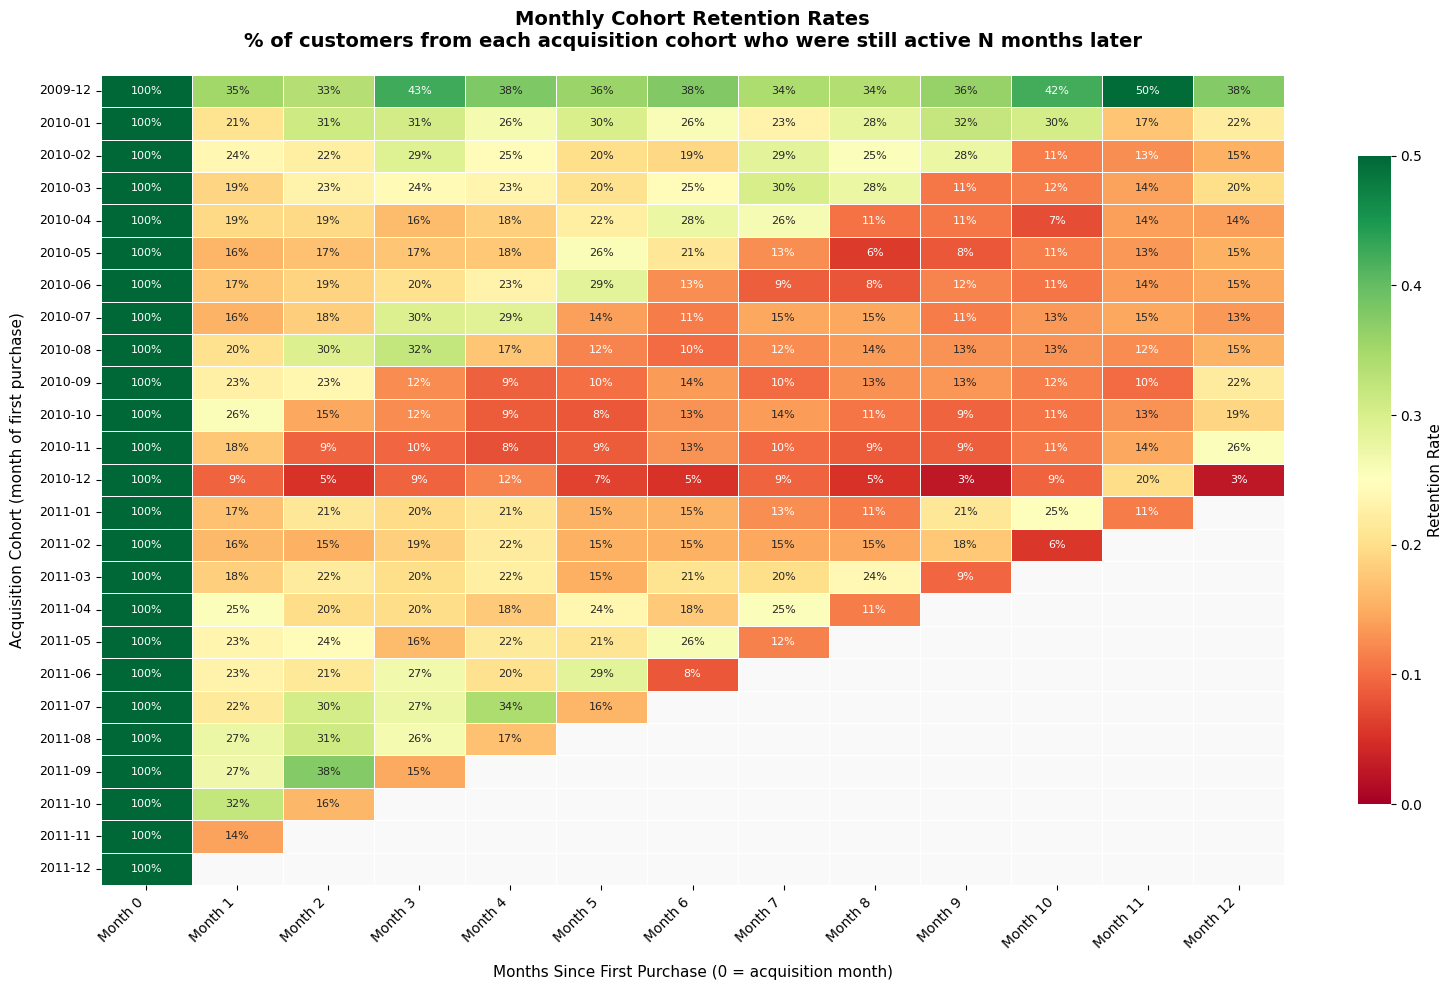


How to read this chart:
- Each ROW is a group of customers acquired in the same month (their 'cohort')
- Each COLUMN is how many months have passed since they were acquired
- The VALUE in each cell is: what % of that cohort was still active that month
- Column 0 is always 100% — every customer was active when they first joined
- Reading ACROSS a row shows how a single cohort retains over time
- Reading DOWN a column shows whether newer cohorts retain better than older ones


In [ ]:
# Limit to first 13 columns (month 0 through month 12) for readability
# Cohorts acquired in the last few months won't have 12 months of data yet — that's expected
retention_plot = retention_matrix.iloc[:, :13].copy()

fig, ax = plt.subplots(figsize=(16, 10))

sns.heatmap(
    retention_plot,
    annot=True,
    fmt='.0%',
    cmap='RdYlGn',
    vmin=0,
    vmax=0.5,          # cap at 50% — most e-commerce retention sits in this range
    linewidths=0.5,
    linecolor='white',
    ax=ax,
    cbar_kws={'label': 'Retention Rate', 'shrink': 0.8},
    annot_kws={'size': 8},
)

ax.set_title(
    'Monthly Cohort Retention Rates\n'
    '% of customers from each acquisition cohort who were still active N months later',
    fontsize=14, fontweight='bold', pad=20
)
ax.set_xlabel('Months Since First Purchase (0 = acquisition month)', fontsize=11, labelpad=10)
ax.set_ylabel('Acquisition Cohort (month of first purchase)', fontsize=11, labelpad=10)
ax.set_yticklabels([str(p) for p in retention_plot.index], rotation=0, fontsize=9)
ax.set_xticklabels([f'Month {i}' for i in retention_plot.columns], rotation=45, ha='right')

plt.tight_layout()
plt.savefig(FIGURES / '07_cohort_retention_heatmap.png', dpi=150, bbox_inches='tight')
plt.show()

print("\nHow to read this chart:")
print("- Each ROW is a group of customers acquired in the same month (their 'cohort')")
print("- Each COLUMN is how many months have passed since they were acquired")
print("- The VALUE in each cell is: what % of that cohort was still active that month")
print("- Column 0 is always 100% — every customer was active when they first joined")
print("- Reading ACROSS a row shows how a single cohort retains over time")
print("- Reading DOWN a column shows whether newer cohorts retain better than older ones")


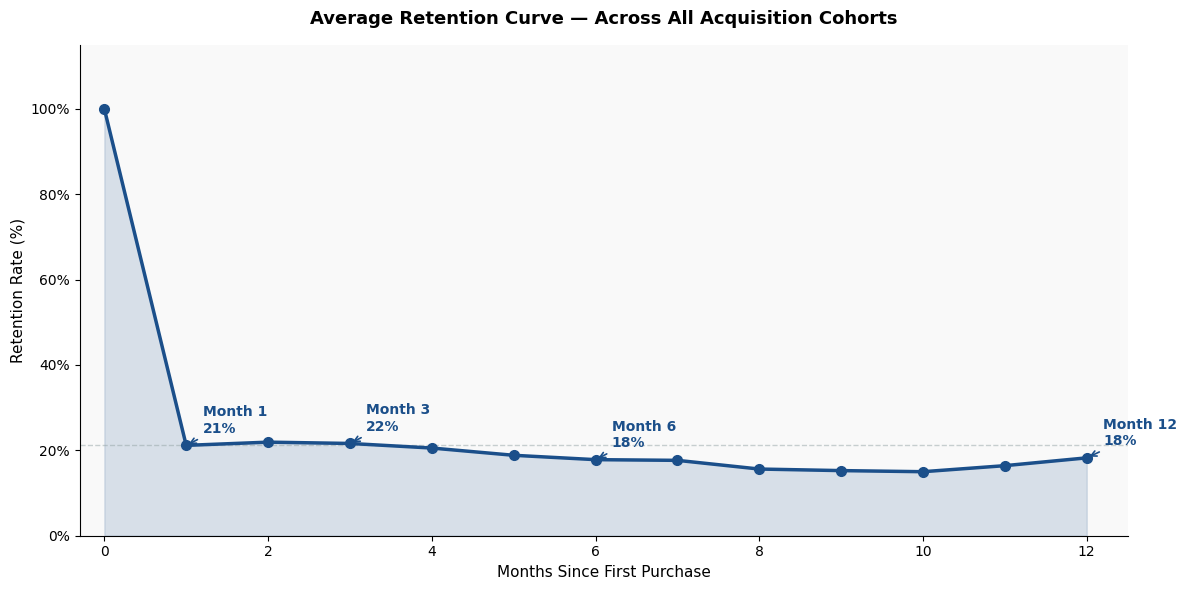

Key retention milestones (average across all cohorts):
  Month  1: 21% of customers still active
  Month  2: 22% of customers still active
  Month  3: 22% of customers still active
  Month  6: 18% of customers still active
  Month 12: 18% of customers still active


In [ ]:
# Average retention across all cohorts at each time point
avg_retention = retention_matrix.iloc[:, :13].mean()

fig, ax = plt.subplots(figsize=(12, 6))

ax.fill_between(avg_retention.index, avg_retention.values * 100, alpha=0.15, color=BLUE)
ax.plot(avg_retention.index, avg_retention.values * 100,
        color=BLUE, lw=2.5, marker='o', ms=7, zorder=5)

# Annotate key milestones
for month in [1, 3, 6, 12]:
    if month in avg_retention.index and not pd.isna(avg_retention[month]):
        val = avg_retention[month]
        ax.annotate(
            f'Month {month}\n{val*100:.0f}%',
            xy=(month, val * 100),
            xytext=(month + 0.2, val * 100 + 3),
            fontsize=10, fontweight='bold', color=BLUE,
            arrowprops={'arrowstyle': '->', 'color': BLUE, 'lw': 1.2}
        )

ax.set_title('Average Retention Curve — Across All Acquisition Cohorts', fontweight='bold', pad=15)
ax.set_xlabel('Months Since First Purchase')
ax.set_ylabel('Retention Rate (%)')
ax.set_xlim(-0.3, 12.5)
ax.set_ylim(0, 115)
ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: f'{v:.0f}%'))
ax.axhline(y=avg_retention[1] * 100, color=GREY, linestyle='--', alpha=0.5, lw=1)

plt.tight_layout()
plt.savefig(FIGURES / '08_avg_retention_curve.png', dpi=150, bbox_inches='tight')
plt.show()

print("Key retention milestones (average across all cohorts):")
for m in [1, 2, 3, 6, 12]:
    if m in avg_retention.index and not pd.isna(avg_retention[m]):
        print(f"  Month {m:>2}: {avg_retention[m]*100:.0f}% of customers still active")


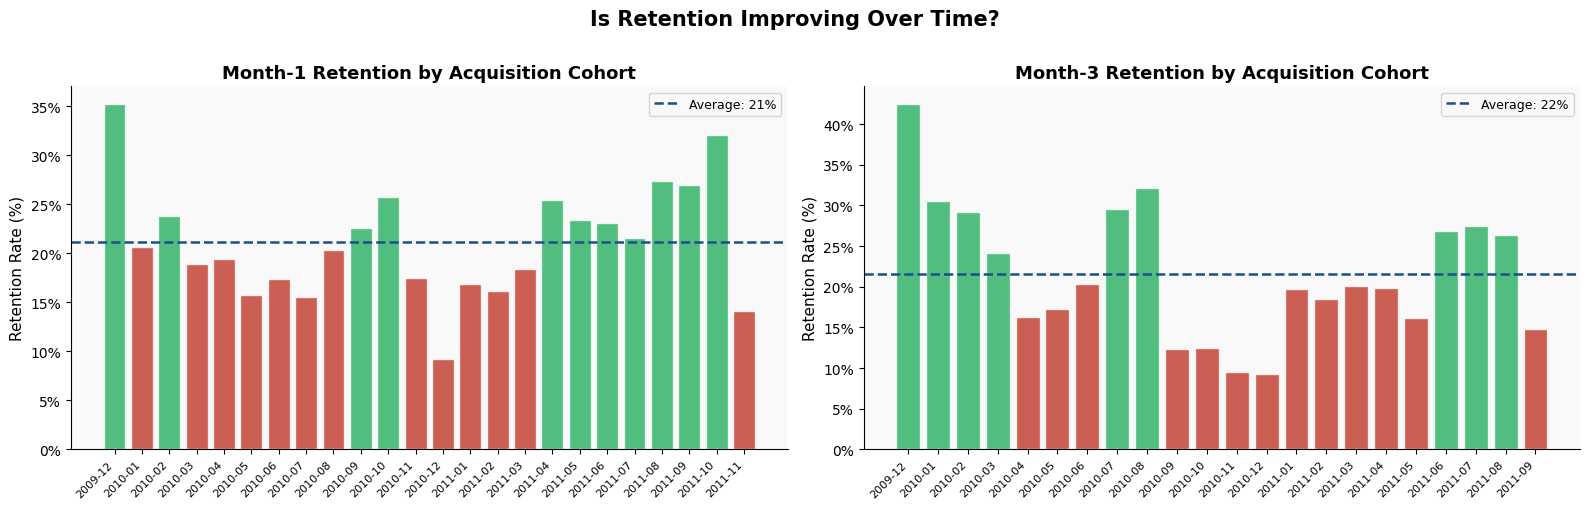

Month-1 retention — average : 21%
Month-1 retention — best    : 35%  (cohort: 2009-12)
Month-1 retention — worst   : 9%  (cohort: 2010-12)

Month-3 retention — average : 22%
Month-3 retention — best    : 43%  (cohort: 2009-12)
Month-3 retention — worst   : 9%  (cohort: 2010-12)


In [ ]:
# Month-1 retention = the most reliable early signal of cohort quality
# (Did customers come back after their very first purchase?)
m1_retention = retention_matrix[1].dropna()
m3_retention = retention_matrix[3].dropna()

fig, axes = plt.subplots(1, 2, figsize=(16, 5))
fig.suptitle('Is Retention Improving Over Time?', fontsize=15, fontweight='bold', y=1.01)

for ax, data, title, month in [
    (axes[0], m1_retention, 'Month-1 Retention by Acquisition Cohort', 1),
    (axes[1], m3_retention, 'Month-3 Retention by Acquisition Cohort', 3),
]:
    avg = data.mean()
    labels = [str(c) for c in data.index]
    colors = [GREEN if v >= avg else RED for v in data.values]

    ax.bar(range(len(labels)), data.values * 100, color=colors, alpha=0.8, edgecolor='white')
    ax.axhline(avg * 100, color=BLUE, linestyle='--', lw=1.8,
               label=f'Average: {avg*100:.0f}%')
    ax.set_title(title, fontweight='bold')
    ax.set_ylabel('Retention Rate (%)')
    ax.set_xticks(range(len(labels)))
    ax.set_xticklabels(labels, rotation=45, ha='right', fontsize=8)
    ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: f'{v:.0f}%'))
    ax.legend(fontsize=9)

plt.tight_layout()
plt.savefig(FIGURES / '09_cohort_retention_trend.png', dpi=150, bbox_inches='tight')
plt.show()

print(f"Month-1 retention — average : {m1_retention.mean()*100:.0f}%")
print(f"Month-1 retention — best    : {m1_retention.max()*100:.0f}%  (cohort: {m1_retention.idxmax()})")
print(f"Month-1 retention — worst   : {m1_retention.min()*100:.0f}%  (cohort: {m1_retention.idxmin()})")
print()
print(f"Month-3 retention — average : {m3_retention.mean()*100:.0f}%")
print(f"Month-3 retention — best    : {m3_retention.max()*100:.0f}%  (cohort: {m3_retention.idxmax()})")
print(f"Month-3 retention — worst   : {m3_retention.min()*100:.0f}%  (cohort: {m3_retention.idxmin()})")


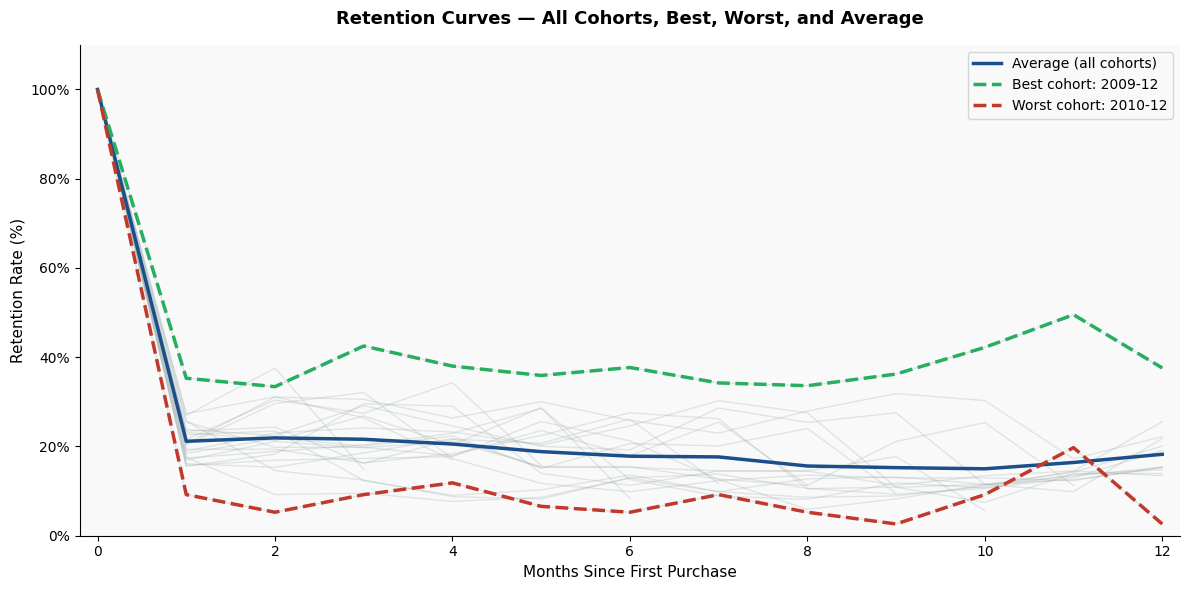

In [ ]:
# Identify the best and worst retaining cohorts (by month-3 retention)
best_cohort  = m3_retention.idxmax()
worst_cohort = m3_retention.idxmin()
avg_curve    = retention_matrix.iloc[:, :13].mean()

fig, ax = plt.subplots(figsize=(12, 6))

# Plot all cohorts as faint lines in the background
for cohort in retention_matrix.index:
    row = retention_matrix.loc[cohort, :12].dropna()
    if len(row) >= 4:
        ax.plot(row.index, row.values * 100, color=GREY, alpha=0.25, lw=1)

# Highlight average, best, worst
ax.plot(avg_curve.index,
        avg_curve.values * 100,
        color=BLUE, lw=2.5, label='Average (all cohorts)', zorder=4)

best_row = retention_matrix.loc[best_cohort, :12].dropna()
ax.plot(best_row.index, best_row.values * 100,
        color=GREEN, lw=2.5, linestyle='--',
        label=f'Best cohort: {best_cohort}', zorder=5)

worst_row = retention_matrix.loc[worst_cohort, :12].dropna()
ax.plot(worst_row.index, worst_row.values * 100,
        color=RED, lw=2.5, linestyle='--',
        label=f'Worst cohort: {worst_cohort}', zorder=5)

ax.set_title('Retention Curves — All Cohorts, Best, Worst, and Average',
             fontweight='bold', pad=15)
ax.set_xlabel('Months Since First Purchase')
ax.set_ylabel('Retention Rate (%)')
ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: f'{v:.0f}%'))
ax.legend(fontsize=10)
ax.set_xlim(-0.2, 12.2)
ax.set_ylim(0, 110)

plt.tight_layout()
plt.savefig(FIGURES / '10_best_worst_cohorts.png', dpi=150, bbox_inches='tight')
plt.show()


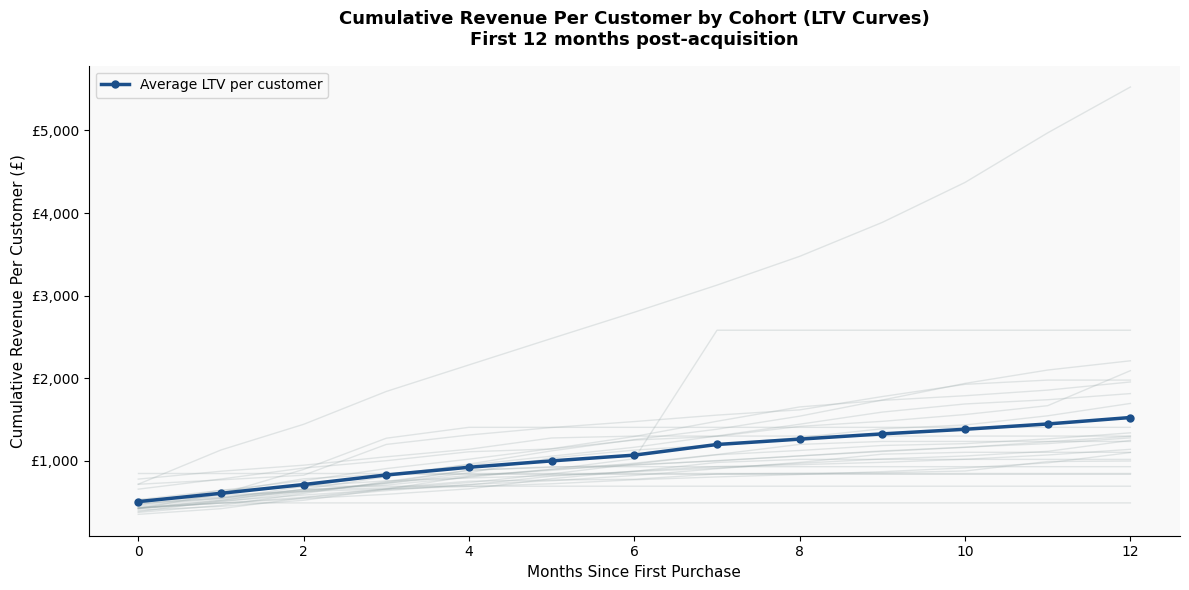

Average cumulative LTV per customer by month:
  Month  1: £609
  Month  3: £831
  Month  6: £1,071
  Month 12: £1,526


In [ ]:
# Revenue per cohort per month
cohort_rev = (
    retail
    .groupby(['CohortMonth', 'CohortIndex'])['Revenue']
    .sum()
    .reset_index()
)

cohort_rev_pivot = cohort_rev.pivot(
    index='CohortMonth',
    columns='CohortIndex',
    values='Revenue'
).fillna(0)

# Cumulative revenue per customer — divide by cohort size
cum_rev_per_cust = cohort_rev_pivot.iloc[:, :13].cumsum(axis=1).divide(cohort_size, axis=0)
avg_cum_ltv = cum_rev_per_cust.mean()

fig, ax = plt.subplots(figsize=(12, 6))

for cohort in cum_rev_per_cust.index:
    row = cum_rev_per_cust.loc[cohort].dropna()
    if len(row) >= 4:
        ax.plot(row.index, row.values, color=GREY, alpha=0.25, lw=1)

ax.plot(avg_cum_ltv.index, avg_cum_ltv.values,
        color=BLUE, lw=2.5, marker='o', ms=5, label='Average LTV per customer')

ax.set_title('Cumulative Revenue Per Customer by Cohort (LTV Curves)\nFirst 12 months post-acquisition',
             fontweight='bold', pad=15)
ax.set_xlabel('Months Since First Purchase')
ax.set_ylabel('Cumulative Revenue Per Customer (£)')
ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: f'£{v:,.0f}'))
ax.legend(fontsize=10)

plt.tight_layout()
plt.savefig(FIGURES / '11_cohort_ltv_curves.png', dpi=150, bbox_inches='tight')
plt.show()

print("Average cumulative LTV per customer by month:")
for m in [1, 3, 6, 12]:
    if m in avg_cum_ltv.index and not pd.isna(avg_cum_ltv[m]):
        print(f"  Month {m:>2}: £{avg_cum_ltv[m]:,.0f}")
